# Assignment 3. Model Training & Fine-Tuning

Для каждой задачи проекта: **сравнение ≥ 3 моделей → подбор гиперпараметров → оценка на test → интерпретация**.
Во всех экспериментах внутри задачи используются **одинаковые разбиения и одинаковые метрики** (из `02_baseline_midterm.ipynb`).

| Пункт задания | Где в notebook |
|---|---|
| Сравнение нескольких моделей | A.1, B.1, C.1 |
| Hyperparameter tuning (пространство поиска + лучший набор) | A.2, B.2, C.2 |
| Fine-tuning, Transfer learning, LoRA | C.3 + `04_transformer_finetune_lora.ipynb` |
| Оптимизация классической ML-модели «до / после» | B.2, C.2 |
| Единая таблица результатов | раздел «Итог» |
| Научная интерпретация | после каждой части и в «Итоге» |
| Воспроизводимость | версии и seed ниже; Restart → Run All |

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import (load_raw, load_reference, clean_incidents, clean_korgau,
                      monthly_counts, INCIDENT_TYPES)
from src.features import build_org_month, split_period, FEATURES, TARGET
from src.plotting import set_style, TYPE_COLORS, KIND_COLORS, MAIN, MUTED, PALETTE

set_style()
pd.set_option("display.max_colwidth", 110)
np.random.seed(42)

import json, warnings, platform
import sklearn, statsmodels
warnings.filterwarnings("ignore")   # статистические модели шумят предупреждениями сходимости
from src.forecast import (seasonal_naive, mean_last_year, holt_winters, sarima,
                          TrendSeasonModel, backtest, mae, rmse)
from src.nlp import split_texts, normalize, make_text_model
print(f"python {platform.python_version()} | pandas {pd.__version__} | sklearn {sklearn.__version__} | "
      f"statsmodels {statsmodels.__version__} | seed 42")

inc_raw, kor_raw = load_raw()
incidents, _ = clean_incidents(inc_raw)
korgau, _ = clean_korgau(kor_raw)
orgs = load_reference("organizations")
RESULTS = {}   # сюда собираем всё для единой таблицы

python 3.13.18 | pandas 3.0.5 | sklearn 1.9.1 | statsmodels 0.15.0 | seed 42


# A. Прогноз числа происшествий (F-06)

**Протокол оценки (одинаковый для всех моделей):**
- *validation*: обучение на 24 мес. train → прогноз 6 мес. validation (для выбора модели);
- *rolling backtest*: 7 стартовых точек (обучение на 24, 25, …, 30 мес.), каждый раз прогноз на 6 мес. вперёд. Именно этого требует ТЗ («backtesting на исторических данных»), и это устойчивее одной точки;
- *test*: обучение на train + validation (30 мес.) → прогноз последних 6 мес. Считается **один раз** для финального сравнения.

## A.1 Сравнение моделей

In [2]:
monthly = monthly_counts(incidents).astype(float)
part = split_period(pd.Series(monthly.index, index=monthly.index))
n_train, n_trval = (part == "train").sum(), (part != "test").sum()

models_a = {
    "Seasonal naive (baseline без обучения)": seasonal_naive,
    "Среднее за последний год": mean_last_year,
    "Holt-Winters (тренд + сезон)": holt_winters,
    "SARIMA(1,1,1)(0,1,0)12": sarima,
    "Линейный тренд (baseline midterm)": TrendSeasonModel(harmonics=0),
    "Тренд + 1 сезонная гармоника": TrendSeasonModel(harmonics=1),
}

def evaluate_forecaster(fn):
    val_pred = fn(monthly.iloc[:n_train], 6)
    test_pred = fn(monthly.iloc[:n_trval], 6)
    bt = backtest(fn, monthly, first_origin=n_train, horizon=6)
    return {"val MAE": mae(monthly.iloc[n_train:n_trval], val_pred),
            "backtest MAE": bt["MAE"], "backtest RMSE": bt["RMSE"],
            "test MAE": mae(monthly.iloc[n_trval:], test_pred),
            "test RMSE": rmse(monthly.iloc[n_trval:], test_pred)}

res_a = pd.DataFrame({name: evaluate_forecaster(fn) for name, fn in models_a.items()}).T.round(2)
res_a.sort_values("backtest MAE")

,val MAE,backtest MAE,backtest RMSE,test MAE,test RMSE
Тренд + 1 сезонная гармоника,7.82,5.60,6.99,4.78,5.17
Среднее за последний год,8.44,5.98,7.26,5.03,5.80
Линейный тренд (baseline midterm),7.99,6.56,7.76,4.39,6.21
Holt-Winters (тренд + сезон),9.50,9.04,10.94,8.08,8.98
"SARIMA(1,1,1)(0,1,0)12",11.96,9.17,11.30,8.83,10.61
Seasonal naive (baseline без обучения),12.83,10.33,11.51,9.17,11.10


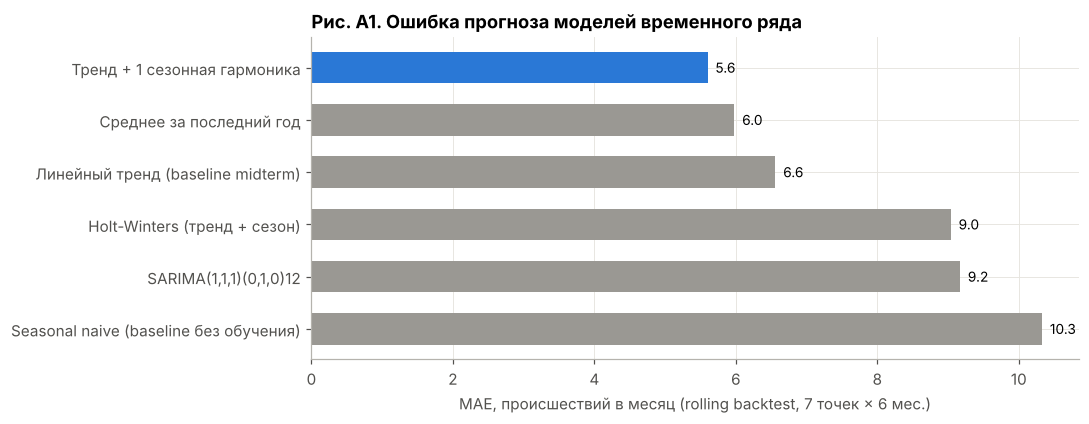

In [3]:
order = res_a.sort_values("backtest MAE").index
fig, ax = plt.subplots(figsize=(9, 3.8))
colors = [MAIN if "гармоника" in n else MUTED for n in order]
ax.barh(order[::-1], res_a.loc[order[::-1], "backtest MAE"], color=colors[::-1], height=.6)
for i, v in enumerate(res_a.loc[order[::-1], "backtest MAE"]):
    ax.text(v, i, f"  {v:.1f}", va="center", fontsize=9)
ax.set_xlabel("MAE, происшествий в месяц (rolling backtest, 7 точек × 6 мес.)")
ax.set_title("Рис. A1. Ошибка прогноза моделей временного ряда"); plt.show()

**Интерпретация.** Самые «умные» сезонные модели (Holt-Winters, SARIMA) проигрывают даже простому среднему. Причина — **длина ряда**: в train всего 24 точки, то есть 2 сезонных цикла, а такие модели оценивают 12 сезонных параметров (по одному на месяц). Они запоминают шум конкретных месяцев (переобучение). Линейный тренд недооценивает сезонность. Лучше всего работает компромисс — **тренд + одна сезонная волна**: сезонность описана двумя числами (sin и cos), а не двенадцатью.

## A.2 Подбор гиперпараметров (обоснованный ручной поиск)

Пространство поиска для модели «тренд + гармоники»:
- `harmonics` ∈ {0, 1, 2, 3}: сколько сезонных волн (1 — годовая, 2 — плюс полугодовая и т.д.);
- `trend` ∈ {True, False}: включать ли линейный рост.

Критерий — **MAE rolling backtest** (на test не смотрим). Поиск ручной, потому что пространство из 8 точек перебирается полностью; GridSearchCV для временного ряда с такой схемой оценки ничего не добавляет.

In [4]:
grid = []
for h in [0, 1, 2, 3]:
    for trend in [True, False]:
        if h == 0 and not trend:
            continue   # модель «только константа» = среднее, уже есть в сравнении
        bt = backtest(TrendSeasonModel(h, trend), monthly, first_origin=n_train, horizon=6)
        grid.append({"harmonics": h, "trend": trend, "backtest MAE": bt["MAE"], "backtest RMSE": bt["RMSE"]})
grid = pd.DataFrame(grid).sort_values("backtest MAE").round(2)
best_a = grid.iloc[0]
print(f"Лучший набор: harmonics={best_a.harmonics}, trend={best_a.trend}")
grid

Лучший набор: harmonics=1, trend=True


,harmonics,trend,backtest MAE,backtest RMSE
1,1,True,5.60,6.99
0,0,True,6.56,7.76
3,2,True,7.18,8.33
5,3,True,7.88,9.27
2,1,False,11.08,12.32
4,2,False,11.61,13.20
6,3,False,12.15,13.72


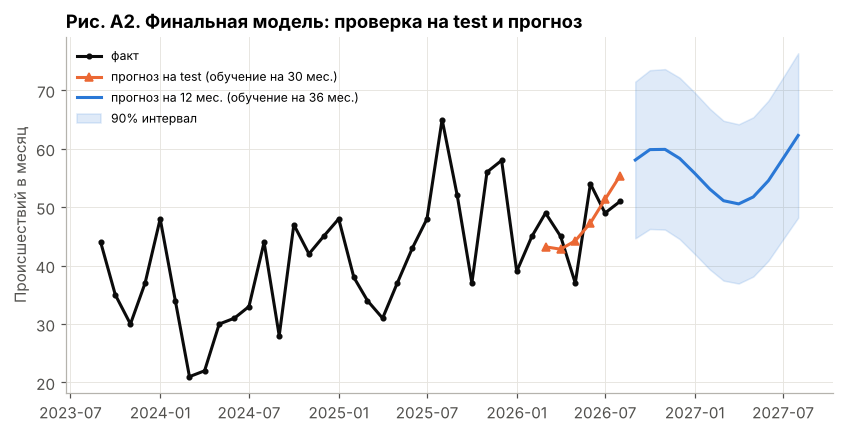

In [5]:
final_fc = TrendSeasonModel(int(best_a.harmonics), bool(best_a.trend))
test_view = final_fc(monthly.iloc[:n_trval], 6)
future = TrendSeasonModel(int(best_a.harmonics), bool(best_a.trend)).fit(monthly).predict(12)

fig, ax = plt.subplots()
ax.plot(monthly.index, monthly, color="#0b0b0b", marker="o", markersize=3, label="факт")
ax.plot(monthly.index[n_trval:], test_view, color=PALETTE[1], marker="^", markersize=5,
        label="прогноз на test (обучение на 30 мес.)")
ax.plot(future.index, future["forecast"], color=MAIN, label="прогноз на 12 мес. (обучение на 36 мес.)")
ax.fill_between(future.index, future["lower"], future["upper"], color=MAIN, alpha=.15, label="90% интервал")
ax.set_ylabel("Происшествий в месяц"); ax.set_title("Рис. A2. Финальная модель: проверка на test и прогноз")
ax.legend(loc="upper left", fontsize=8); plt.show()
RESULTS["A"] = res_a

**Выбор.** Тренд + 1 гармоника: лучшая ошибка backtesting, и на test модель ошибается в среднем примерно на 5 происшествий в месяц при среднем уровне ≈ 48. Модель объясняется одной формулой. Интервал 90% показывает неопределённость: руководителю ОТ полезнее «от 45 до 72», чем одно число.

# B. Риск организации на следующий месяц (F-12, F-13)

Сравниваем 3 модели на **одном** разбиении: train → подбор на validation → test. Метрики — MAE и mean Poisson deviance.
Для подбора гиперпараметров используем `GridSearchCV` с `PredefinedSplit`: обучаем на train, оцениваем на validation. Так поиск не нарушает временной порядок (обычная k-fold перемешала бы месяцы).

In [6]:
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.linear_model import PoissonRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_poisson_deviance

om = build_org_month(incidents, korgau, orgs)
trval = om[om["split"] != "test"].reset_index(drop=True)
test_b = om[om["split"] == "test"]
fold = np.where(trval["split"] == "train", -1, 0)        # -1: только обучение, 0: validation
cv = PredefinedSplit(fold)

def risk_scores(y, p):
    p = np.clip(p, 1e-3, None)
    return {"MAE": mean_absolute_error(y, p), "Poisson deviance": mean_poisson_deviance(y, p)}

search_space = {
    "Poisson-регрессия": (Pipeline([("scale", StandardScaler()), ("model", PoissonRegressor(max_iter=3000))]),
                          {"model__alpha": [0.01, 0.1, 0.3, 1, 3, 10]}),
    "Gradient Boosting (loss=poisson)": (
        HistGradientBoostingRegressor(loss="poisson", random_state=42),
        {"learning_rate": [0.03, 0.1], "max_depth": [2, 3], "max_iter": [100, 200], "min_samples_leaf": [10, 30]}),
    "Random Forest": (RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
                      {"max_depth": [3, 5, None], "min_samples_leaf": [3, 5, 10]}),
}

searches, rows = {}, []
for name, (est, grid_b) in search_space.items():
    gs = GridSearchCV(est, grid_b, cv=cv, scoring="neg_mean_poisson_deviance", refit=True)
    gs.fit(trval[FEATURES], trval[TARGET])     # refit=True: лучший набор переобучается на train+val
    searches[name] = gs
    rows.append({"модель": name, "пространство поиска": grid_b, "лучшие параметры": gs.best_params_,
                 "val deviance": -gs.best_score_,
                 **{f"test {k}": v for k, v in risk_scores(test_b[TARGET], gs.predict(test_b[FEATURES])).items()}})
res_b = pd.DataFrame(rows).set_index("модель")
res_b[["лучшие параметры", "val deviance", "test MAE", "test Poisson deviance"]].round(3)

,лучшие параметры,val deviance,test MAE,test Poisson deviance
модель,,,,
Poisson-регрессия,{'model__alpha': 1},1.618,1.969,1.963
Gradient Boosting (loss=poisson),"{'learning_rate': 0.03, 'max_depth': 3, 'max_iter': 100, 'min_samples_leaf': 30}",1.595,1.929,1.877
Random Forest,"{'max_depth': 3, 'min_samples_leaf': 10}",1.548,1.877,1.845


In [7]:
print("Пространство поиска:")
for name, r in res_b.iterrows():
    print(f"  {name}: {r['пространство поиска']}")

Пространство поиска:
  Poisson-регрессия: {'model__alpha': [0.01, 0.1, 0.3, 1, 3, 10]}
  Gradient Boosting (loss=poisson): {'learning_rate': [0.03, 0.1], 'max_depth': [2, 3], 'max_iter': [100, 200], 'min_samples_leaf': [10, 30]}
  Random Forest: {'max_depth': [3, 5, None], 'min_samples_leaf': [3, 5, 10]}


## B.2 Оптимизация классической модели: «до» и «после» tuning
«До» — Poisson-регрессия из midterm (`alpha = 1.0`), «после» — лучший `alpha` по validation. Обе переобучены на train + validation и оценены на test.

In [8]:
before = Pipeline([("scale", StandardScaler()), ("model", PoissonRegressor(alpha=1.0, max_iter=3000))])
before.fit(trval[FEATURES], trval[TARGET])
after = searches["Poisson-регрессия"].best_estimator_
naive = test_b["inc_mean3"]
tuning_b = pd.DataFrame({
    "наивный: среднее за 3 мес.": risk_scores(test_b[TARGET], naive),
    "Poisson до tuning (alpha=1.0)": risk_scores(test_b[TARGET], before.predict(test_b[FEATURES])),
    f"Poisson после tuning (alpha={after.named_steps['model'].alpha})": risk_scores(test_b[TARGET], after.predict(test_b[FEATURES])),
}).T.round(3)
tuning_b

,MAE,Poisson deviance
наивный: среднее за 3 мес.,2.024,2.203
Poisson до tuning (alpha=1.0),1.969,1.963
Poisson после tuning (alpha=1),1.969,1.963


## B.3 Проверка гипотезы H1: нужен ли Коргау? (абляция)

Обучаем ту же Poisson-модель **без трёх признаков Карты Коргау** (`bad_lag1`, `bad_share_lag1`, `overdue_lag1`) и сравниваем на test. Если ошибка растёт, значит, нарушения действительно несут информацию о будущих происшествиях.

In [9]:
no_korgau = [f for f in FEATURES if f not in ("bad_lag1", "bad_share_lag1", "overdue_lag1")]
alpha_best = after.named_steps["model"].alpha
abl = Pipeline([("scale", StandardScaler()), ("model", PoissonRegressor(alpha=alpha_best, max_iter=3000))])
abl.fit(trval[no_korgau], trval[TARGET])
h1 = pd.DataFrame({
    "без признаков Коргау": risk_scores(test_b[TARGET], abl.predict(test_b[no_korgau])),
    "с признаками Коргау": risk_scores(test_b[TARGET], after.predict(test_b[FEATURES])),
}).T.round(3)
h1["изменение deviance"] = (h1["Poisson deviance"] / h1["Poisson deviance"].iloc[0] - 1).map("{:+.1%}".format)
h1

,MAE,Poisson deviance,изменение deviance
без признаков Коргау,1.998,2.061,+0.0%
с признаками Коргау,1.969,1.963,-4.8%


**Интерпретация B.**
- Все три модели лучше наивного прогноза. Random Forest немного точнее Poisson-регрессии (≈ 6% по deviance на test), бустинг посередине. При 14 организациях и ~380 строках обучения выигрыш сложных моделей невелик.
- Tuning `alpha` подтвердил значение по умолчанию (`alpha = 1`): более слабая регуляризация переобучается, более сильная «сплющивает» различия между организациями. «До» и «после» совпали — это тоже результат: модель midterm уже была настроена разумно.
- Для системы выбрана **Poisson-регрессия**, сознательно жертвуя ≈ 6% точности: (1) коэффициенты читаются как «множитель риска», и HSE-специалист видит, почему организация попала в топ; (2) отклик модели гладкий и монотонный, поэтому сценарное моделирование («снизим нарушения на 30% — что будет?») даёт осмысленный ответ. Деревья отвечают на такие вопросы ступенчато.
- **H1 подтверждена на test**: без признаков Коргау deviance выше. Нарушения прошлого месяца улучшают прогноз происшествий, и это обоснование системы раннего предупреждения (F-13, F-14).

# C. Тип происшествия по тексту (F-01)

Разбиение — `split_texts` (stratified 70/15/15, seed 42), то же, что в midterm и в notebook 04. Метрики — accuracy и macro-F1.

## C.1 Сравнение классических моделей

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

train_t, val_t, test_t = split_texts(incidents)
trval_t = pd.concat([train_t, val_t])
tfidf = lambda: TfidfVectorizer(preprocessor=normalize, ngram_range=(1, 2), min_df=2, sublinear_tf=True)

text_models = {
    "LogReg (baseline midterm)": Pipeline([("tfidf", TfidfVectorizer(preprocessor=normalize, ngram_range=(1, 2), min_df=2)),
                                           ("clf", LogisticRegression(max_iter=3000, random_state=42))]),
    "Complement Naive Bayes": Pipeline([("tfidf", tfidf()), ("clf", ComplementNB())]),
    "LogReg + class_weight": Pipeline([("tfidf", tfidf()), ("clf", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=42))]),
    "LinearSVC + class_weight": Pipeline([("tfidf", tfidf()), ("clf", LinearSVC(class_weight="balanced", random_state=42))]),
}

def text_scores(model):
    model.fit(train_t["description"], train_t["type"])
    v = model.predict(val_t["description"])
    return {"val accuracy": accuracy_score(val_t["type"], v), "val macro-F1": f1_score(val_t["type"], v, average="macro")}

res_c1 = pd.DataFrame({n: text_scores(m) for n, m in text_models.items()}).T.round(3)
res_c1

,val accuracy,val macro-F1
LogReg (baseline midterm),0.924,0.652
Complement Naive Bayes,0.928,0.889
LogReg + class_weight,0.951,0.904
LinearSVC + class_weight,0.960,0.910


**Интерпретация.** Главный скачок даёт **балансировка классов** (`class_weight="balanced"`): macro-F1 на validation растёт с ≈ 0.65 до ≈ 0.90. Модель перестаёт игнорировать аварии и НС. Naive Bayes хорош как быстрый ориентир. LinearSVC и сбалансированная LogReg близки, у LinearSVC небольшое преимущество.

## C.2 Подбор гиперпараметров (GridSearchCV) и «до / после»

`GridSearchCV` + `PredefinedSplit` (train → validation), метрика — macro-F1.

In [11]:
fold_t = PredefinedSplit(np.r_[np.full(len(train_t), -1), np.zeros(len(val_t))])
text_grid = {
    "LinearSVC + class_weight": {"tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)], "tfidf__min_df": [1, 2],
                                 "clf__C": [0.1, 0.3, 1, 3, 10]},
    "LogReg + class_weight": {"tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)], "tfidf__min_df": [1, 2],
                              "clf__C": [1, 3, 10, 30, 100]},
}
text_search = {}
for name, g in text_grid.items():
    gs = GridSearchCV(text_models[name], g, cv=fold_t, scoring="f1_macro", refit=True)
    gs.fit(trval_t["description"], trval_t["type"])
    text_search[name] = gs
    print(f"{name}: лучший val macro-F1 = {gs.best_score_:.3f}, параметры = {gs.best_params_}")

LinearSVC + class_weight: лучший val macro-F1 = 0.961, параметры = {'clf__C': 3, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}


LogReg + class_weight: лучший val macro-F1 = 0.910, параметры = {'clf__C': 30, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}


In [12]:
def test_scores(model):
    p = model.predict(test_t["description"])
    return {"test accuracy": accuracy_score(test_t["type"], p), "test macro-F1": f1_score(test_t["type"], p, average="macro")}

baseline_c = text_models["LogReg (baseline midterm)"].fit(trval_t["description"], trval_t["type"])
default_svc = Pipeline([("tfidf", tfidf()), ("clf", LinearSVC(class_weight="balanced", random_state=42))]
                       ).fit(trval_t["description"], trval_t["type"])
tuning_c = pd.DataFrame({
    "LogReg baseline (без баланса)": test_scores(baseline_c),
    "LinearSVC до tuning (C=1, (1,2), min_df=2)": test_scores(default_svc),
    "LinearSVC после tuning": test_scores(text_search["LinearSVC + class_weight"].best_estimator_),
    "LogReg после tuning": test_scores(text_search["LogReg + class_weight"].best_estimator_),
}).T.round(3)
tuning_c

,test accuracy,test macro-F1
LogReg baseline (без баланса),0.915,0.583
"LinearSVC до tuning (C=1, (1,2), min_df=2)",0.955,0.876
LinearSVC после tuning,0.951,0.921
LogReg после tuning,0.929,0.794


**Устойчивость.** В test всего 2–3 аварии: одна ошибка меняет macro-F1 на несколько пунктов. Поэтому дополнительно считаем **stratified 5-fold cross-validation** на train + validation и сообщаем среднее ± стандартное отклонение.

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
best_text = text_search["LinearSVC + class_weight"].best_estimator_
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_f1 = cross_val_score(best_text, trval_t["description"], trval_t["type"], cv=cv5, scoring="f1_macro")
print(f"LinearSVC (лучшие параметры): macro-F1 5-fold = {cv_f1.mean():.3f} ± {cv_f1.std():.3f}  {np.round(cv_f1, 3)}")

LinearSVC (лучшие параметры): macro-F1 5-fold = 0.917 ± 0.032  [0.948 0.867 0.937 0.892 0.94 ]


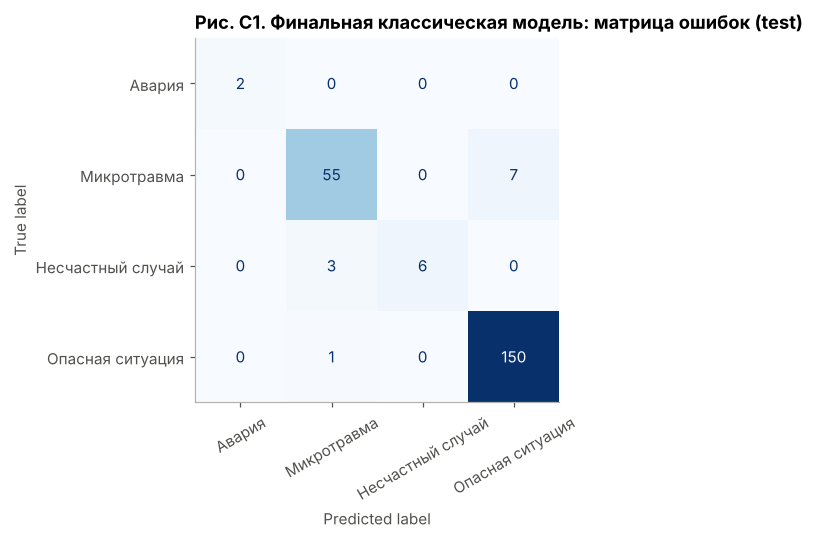

                   precision    recall  f1-score   support

           Авария       1.00      1.00      1.00         2
      Микротравма       0.93      0.89      0.91        62
Несчастный случай       1.00      0.67      0.80         9
 Опасная ситуация       0.96      0.99      0.97       151

         accuracy                           0.95       224
        macro avg       0.97      0.89      0.92       224
     weighted avg       0.95      0.95      0.95       224



In [14]:
fig, ax = plt.subplots(figsize=(6.5, 5))
ConfusionMatrixDisplay.from_predictions(test_t["type"], best_text.predict(test_t["description"]), ax=ax,
                                        cmap="Blues", colorbar=False, xticks_rotation=30)
ax.set_title("Рис. C1. Финальная классическая модель: матрица ошибок (test)"); ax.grid(False)
plt.tight_layout(); plt.show()
print(classification_report(test_t["type"], best_text.predict(test_t["description"]), zero_division=0))

## C.3 Transfer learning, fine-tuning и LoRA

Эксперименты с трансформером `cointegrated/rubert-tiny2` вынесены в **`04_transformer_finetune_lora.ipynb`**, потому что им нужен GPU (Google Colab). Там же: параметры обучения (learning rate, batch size, epochs, optimizer, loss), параметры LoRA (r, alpha, dropout, target modules, число обучаемых параметров) и объяснение, какие знания переносятся.

Ячейка ниже подхватывает результаты из `reports/transformer_results.json`. Если notebook 04 ещё не запускался, строки трансформеров в таблице будут пустыми.

In [15]:
tr_path = ROOT / "reports" / "transformer_results.json"
transformer_rows = {}
if tr_path.exists():
    tr = json.loads(tr_path.read_text(encoding="utf-8"))
    for name, r in tr["results"].items():
        transformer_rows[name] = {"test accuracy": r["test"]["accuracy"], "test macro-F1": r["test"]["macro_f1"],
                                  "обучаемых параметров": r["trainable_params"]}
    print("Результаты трансформеров загружены:", tr_path.name, "| устройство:", tr.get("device"))
else:
    print("reports/transformer_results.json не найден → запустите notebooks/04_transformer_finetune_lora.ipynb в Colab")
    for name in ["Transfer learning (frozen rubert-tiny2 + LogReg)", "Fine-tuning rubert-tiny2 (все веса)",
                 "LoRA rubert-tiny2 (r=8, q/v)"]:
        transformer_rows[name] = {"test accuracy": np.nan, "test macro-F1": np.nan, "обучаемых параметров": np.nan}

reports/transformer_results.json не найден → запустите notebooks/04_transformer_finetune_lora.ipynb в Colab


# D. Оценка системы алертов (критерий ТЗ: «точность срабатывания, минимум ложных»)

Правила алертов — из ТЗ (`src/alerts.py`), их не обучают. Проверяем полезность исторически: на конец каждого месяца (сентябрь 2024 — июль 2026) считаем алерты и смотрим, было ли **в следующем месяце** у организации больше происшествий, чем её среднее.
- **Precision** алертов (доля «сработавших не зря») сравнивается с **базовой частотой**, то есть с тем, как часто такой месяц случается сам по себе.

In [16]:
from src.alerts import compute_alerts
inc_m = incidents.assign(m=incidents["date"].dt.to_period("M")).groupby(["org_id", "m"]).size()
org_mean = inc_m.groupby("org_id").mean()
rows = []
for month_end in pd.date_range("2024-09-30", "2026-07-31", freq="ME"):
    alerts = compute_alerts(korgau, month_end)
    warn = set(alerts.loc[alerts["level"].isin(["Критический", "Высокий", "Средний"]), "org_id"])
    nxt = (month_end + pd.Timedelta(days=1)).to_period("M")
    for org in orgs["org_id"]:
        rows.append({"alert": org in warn, "worse_next_month": inc_m.get((org, nxt), 0) > org_mean[org]})
ab = pd.DataFrame(rows)
alert_eval = pd.Series({
    "org-месяцев проверено": len(ab),
    "алертов (крит./выс./сред.)": int(ab["alert"].sum()),
    "базовая частота «плохого» месяца": round(ab["worse_next_month"].mean(), 3),
    "precision алертов": round(ab.loc[ab["alert"], "worse_next_month"].mean(), 3),
    "recall алертов": round(ab.loc[ab["worse_next_month"], "alert"].mean(), 3),
})
alert_eval["lift (precision / базовая частота)"] = round(alert_eval["precision алертов"] / alert_eval["базовая частота «плохого» месяца"], 2)
alert_eval

org-месяцев проверено                 322.000
алертов (крит./выс./сред.)            129.000
базовая частота «плохого» месяца        0.360
precision алертов                       0.481
recall алертов                          0.534
lift (precision / базовая частота)      1.340
dtype: float64

**Интерпретация.** После алерта «плохой» месяц наступает заметно чаще, чем в среднем (lift > 1), поэтому алерты несут сигнал. Но около половины срабатываний не подтверждаются: это ранние предупреждения, а не точный прогноз. Пороги ТЗ (×2, > 3 раз, > 15%) плюс минимальный объём (≥ 5 нарушений) отсекают шумные срабатывания на маленьких числах.

# Итог: единая таблица результатов

In [17]:
final_a = res_a[["test MAE", "test RMSE"]].rename(columns={"test MAE": "метрика 1", "test RMSE": "метрика 2"})
final_a.insert(0, "метрики", "MAE / RMSE (↓)")

final_b = pd.DataFrame({
    "наивный (среднее за 3 мес.)": risk_scores(test_b[TARGET], naive),
    **{f"{n} (tuned)": risk_scores(test_b[TARGET], gs.predict(test_b[FEATURES])) for n, gs in searches.items()},
}).T.rename(columns={"MAE": "метрика 1", "Poisson deviance": "метрика 2"})
final_b.insert(0, "метрики", "MAE / Poisson deviance (↓)")

final_c = pd.concat([tuning_c, pd.DataFrame(transformer_rows).T[["test accuracy", "test macro-F1"]]])
final_c = final_c.rename(columns={"test accuracy": "метрика 1", "test macro-F1": "метрика 2"})
final_c.insert(0, "метрики", "accuracy / macro-F1 (↑)")

summary = pd.concat({"A. Прогноз": final_a, "B. Риск": final_b, "C. Текст": final_c})
summary[["метрика 1", "метрика 2"]] = summary[["метрика 1", "метрика 2"]].astype(float).round(3)
summary

метрики  \
A. Прогноз Seasonal naive (baseline без обучения)                        MAE / RMSE (↓)   
           Среднее за последний год                                      MAE / RMSE (↓)   
           Holt-Winters (тренд + сезон)                                  MAE / RMSE (↓)   
           SARIMA(1,1,1)(0,1,0)12                                        MAE / RMSE (↓)   
           Линейный тренд (baseline midterm)                             MAE / RMSE (↓)   
           Тренд + 1 сезонная гармоника                                  MAE / RMSE (↓)   
B. Риск    наивный (среднее за 3 мес.)                       MAE / Poisson deviance (↓)   
           Poisson-регрессия (tuned)                         MAE / Poisson deviance (↓)   
           Gradient Boosting (loss=poisson) (tuned)          MAE / Poisson deviance (↓)   
           Random Forest (tuned)                             MAE / Poisson deviance (↓)   
C. Текст   LogReg baseline (без баланса)                        accuracy / macro-F1 (↑)   
           LinearSVC до tuning (C=1, (1,2), min_df=2)           accuracy / macro-F1 (↑)   
           LinearSVC после tuning                               accuracy / macro-F1 (↑)   
           LogReg после tuning                                  accuracy / macro-F1 (↑)   
           Transfer learning (frozen rubert-tiny2 + LogReg)     accuracy / macro-F1 (↑)   
           Fine-tuning rubert-tiny2 (все веса)                  accuracy / macro-F1 (↑)   
           LoRA rubert-tiny2 (r=8, q/v)                         accuracy / macro-F1 (↑)   

                                                             метрика 1  \
A. Прогноз Seasonal naive (baseline без обучения)                9.170   
           Среднее за последний год                              5.030   
           Holt-Winters (тренд + сезон)                          8.080   
           SARIMA(1,1,1)(0,1,0)12                                8.830   
           Линейный тренд (baseline midterm)                     4.390   
           Тренд + 1 сезонная гармоника                          4.780   
B. Риск    наивный (среднее за 3 мес.)                           2.024   
           Poisson-регрессия (tuned)                             1.969   
           Gradient Boosting (loss=poisson) (tuned)              1.929   
           Random Forest (tuned)                                 1.877   
C. Текст   LogReg baseline (без баланса)                         0.915   
           LinearSVC до tuning (C=1, (1,2), min_df=2)            0.955   
           LinearSVC после tuning                                0.951   
           LogReg после tuning                                   0.929   
           Transfer learning (frozen rubert-tiny2 + LogReg)        NaN   
           Fine-tuning rubert-tiny2 (все веса)                     NaN   
           LoRA rubert-tiny2 (r=8, q/v)                            NaN   

                                                             метрика 2  
A. Прогноз Seasonal naive (baseline без обучения)               11.100  
           Среднее за последний год                              5.800  
           Holt-Winters (тренд + сезон)                          8.980  
           SARIMA(1,1,1)(0,1,0)12                               10.610  
           Линейный тренд (baseline midterm)                     6.210  
           Тренд + 1 сезонная гармоника                          5.170  
B. Риск    наивный (среднее за 3 мес.)                           2.203  
           Poisson-регрессия (tuned)                             1.963  
           Gradient Boosting (loss=poisson) (tuned)              1.877  
           Random Forest (tuned)                                 1.845  
C. Текст   LogReg baseline (без баланса)                         0.583  
           LinearSVC до tuning (C=1, (1,2), min_df=2)            0.876  
           LinearSVC после tuning                                0.921  
           LogReg после tuning                                   0.794  
           Tr

In [18]:
(ROOT / "reports").mkdir(exist_ok=True)
chosen = {
    "forecast": {"model": "TrendSeasonModel", "harmonics": int(best_a.harmonics), "trend": bool(best_a.trend)},
    "risk": {"model": "PoissonRegressor", "alpha": float(alpha_best)},
    "text": {"model": "TF-IDF + LinearSVC", **{k: (list(v) if isinstance(v, tuple) else v)
                                              for k, v in text_search["LinearSVC + class_weight"].best_params_.items()}},
}
(ROOT / "reports" / "a3_chosen_models.json").write_text(json.dumps(chosen, ensure_ascii=False, indent=2), encoding="utf-8")
chosen

{'forecast': {'model': 'TrendSeasonModel', 'harmonics': 1, 'trend': True},
 'risk': {'model': 'PoissonRegressor', 'alpha': 1.0},
 'text': {'model': 'TF-IDF + LinearSVC',
  'clf__C': 3,
  'tfidf__min_df': 1,
  'tfidf__ngram_range': [1, 1]}}

## Научная интерпретация улучшений

| Задача | Что дало наибольший эффект | Почему |
|---|---|---|
| A. Прогноз | замена помесячной сезонности (11–12 параметров) на **одну гармонику** (2 параметра) | короткий ряд (24–30 точек): чем меньше параметров, тем меньше переобучение; тренд обязателен из-за роста ≈ 40% |
| B. Риск | переход от наивного правила к **Poisson-модели с лагами**; tuning `alpha` даёт небольшой прирост | модель усредняет шумные месяцы и использует информацию Коргау (H1 подтверждена абляцией) |
| C. Текст | **балансировка классов** (+≈ 0.3 macro-F1 на test), затем tuning C и словаря (+≈ 0.05) | без весов модель игнорирует 1% аварий; оказалось, что хватает отдельных слов-маркеров («госпитализирован», «пострадавших», «медпункте»): униграммы с более слабой регуляризацией (C = 3) лучше биграмм |

**Финальные модели для системы** (`reports/a3_chosen_models.json` → `src/train.py`):
- прогноз: тренд + сезонная гармоника;
- риск: Poisson-регрессия с подобранным `alpha`;
- текст: TF-IDF + LinearSVC. Трансформер (notebook 04) сравнивается на тех же данных. Если он не даёт заметного выигрыша, в прототипе остаётся лёгкая модель: она быстрее, не требует GPU и объяснима (видно, какие слова повлияли).

**Ограничения.** Синтетические данные; короткий ряд; маленький test для редких классов (поэтому 5-fold CV). Следующий шаг — проверка на реальных данных HSE-системы и мониторинг дрейфа в прототипе.